# 1. BUSINESS UNDERSTANDING

### 1.1 Pernyataan Masalah
Industri film adalah industri padat modal dengan ketidakpastian finansial tinggi. Keberhasilan film ditentukan banyak faktor (anggaran, pendapatan box office, popularitas, rating), dan sering terjadi disparitas: film berbujet besar bisa gagal di box office, sementara film berbujet kecil bisa untung berlipat. Evaluasi manual terhadap ratusan ribu judul tidak mungkin dilakukan, dan skala datanya sangat beragam (juta hingga miliar dolar untuk uang, satuan untuk rating). Proyek ini memakai data TMDB untuk membangun model regresi yang memprediksi pendapatan (*revenue*) film dari fitur yang sudah diketahui sebelum rilis, sehingga stakeholder dapat menilai kewajaran anggaran dan potensi pendapatan sebelum keputusan diambil.

### 1.2 Stakeholder
* **Rumah produksi:** menilai kelayakan anggaran dan konsep film pada tahap praproduksi.
* **Distributor dan investor:** menilai profil risiko dan imbal hasil sebelum mendanai.
* **Platform streaming/bioskop:** menyusun prioritas akuisisi film.
* **Penonton dan komunitas film:** memahami faktor yang berkaitan dengan kesuksesan film.
* **Tim analis data:** membangun pipeline, model, dan menerjemahkan hasil menjadi wawasan bisnis.

### 1.3 Tujuan (SMART)
* **Specific:** membangun model regresi untuk memprediksi `revenue` dari fitur pra-rilis (anggaran, durasi, genre, bahasa asli, negara produksi, tahun dan bulan rilis; sutradara dan pemeran diuji sebagai fitur tambahan) serta mengidentifikasi fitur paling berpengaruh. `popularity`, `vote_count`, `vote_average`, `imdb_rating`, dan `imdb_votes` tidak dipakai karena baru diketahui setelah rilis (*data leakage*).
* **Measurable:** diukur pada data uji dengan R², MAE, dan RMSE (skala log), MAE dalam juta USD, dan Median APE. Model harus lebih baik dari baseline rata-rata.
* **Achievable:** dataset terbuka dengan >1 juta baris dan puluhan kolom; model berasal dari materi praktikum dan berjalan dengan Python/scikit-learn.
* **Relevant:** mendukung keputusan berisiko tinggi di industri film dan sesuai tujuan praktikum (alur analisis data lengkap).
* **Time-bound:** Business Understanding sampai Cleaning/Preprocessing dikumpulkan 30 Oktober 2026; repository lengkap 22 November 2026; presentasi 23 November - 4 Desember 2026.

### 1.4 Metrik Keberhasilan
| Metrik | Cara dibaca |
| :--- | :--- |
| R² (skala log) | Proporsi variasi log(revenue) yang dijelaskan model; 0 berarti tidak lebih baik dari menebak rata-rata |
| MAE / RMSE (skala log) | Rata-rata selisih prediksi; exp(MAE) menunjukkan prediksi meleset sekitar sekian kali lipat; RMSE lebih menghukum kesalahan besar |
| MAE (juta USD) | Selisih rata-rata pada skala asli, mudah dipahami tetapi didominasi film blockbuster |
| Median APE (%) | Persentase kesalahan tipikal yang tidak terseret film blockbuster |

Dari sisi proses, setiap keputusan (pemilihan fitur, penanganan data hilang, pemilihan model) harus punya alasan yang jelas.

### 1.5 Asumsi dan Batasan
* **Asumsi:** nilai 0 pada `budget`/`revenue` berarti data tidak tercatat; `revenue` mewakili kesuksesan komersial (tanpa biaya pemasaran); data bersifat statis pada tanggal pengambilan, padahal dataset diperbarui harian.
* **Batasan:** banyak film tidak punya budget/revenue sehingga jumlah film yang dimodelkan jauh lebih kecil dari seluruh dataset; faktor seperti franchise, anggaran pemasaran, dan jumlah layar tidak tersedia; hasil bersifat asosiasi, bukan sebab-akibat.

### 1.6 Risiko, Etika, dan Mitigasi
| Risiko | Mitigasi |
| :--- | :--- |
| Kualitas data tidak konsisten (nol, kosong, negatif) | Filter nilai tidak valid, hapus duplikat, dokumentasikan setiap keputusan |
| Bias dataset (dominasi film populer/berbahasa Inggris) | Bandingkan sebaran sebelum dan sesudah filter, laporkan sebagai keterbatasan |
| Kebocoran data (*leakage*) | Hanya memakai fitur pra-rilis; split data sebelum encoding berbasis target |
| Skala fitur sangat berbeda | Transformasi log dan penskalaan pada tahap pemodelan |
| Keterbatasan waktu dan sumber daya | Fitur dibatasi pada yang dapat diolah dengan materi praktikum |

**Etika:** data berasal dari sumber terbuka (Kaggle/TMDB) dan dipakai untuk tujuan akademik dengan mencantumkan sumber dan lisensi; tidak ada data pribadi yang dipakai; hasil dilaporkan apa adanya beserta keterbatasannya.

### 1.7 Nilai Bisnis
Model dan temuan EDA membantu rumah produksi memeriksa kelayakan anggaran, membantu investor dan distributor memperkirakan potensi komersial sebelum rilis, dan membantu platform menyusun prioritas akuisisi, sehingga keputusan berbasis data dan risiko kegagalan finansial berkurang.

---
# 2. TAHAP DATA GATHERING & DATA UNDERSTANDING

### 2.1 Sumber Data & Lisensi
Dataset yang digunakan dalam proyek ini bersumber dari repositori publik Kaggle berjudul **"The Ultimate 1Million Movies Dataset (TMDB + IMDb)"** yang disusun dan diperbarui secara berkala oleh **Alan Vourch**. Dataset ini mengagregasi metadata komprehensif dari The Movie Database (TMDB) API yang dikombinasikan dengan pengidentifikasi IMDb.

* **Nama Dataset:** The Ultimate 1Million Movies Dataset (TMDB Movies Daily Updates)
* **Penyusun:** Alan Vourch
* **Sumber Data:** [Kaggle - TMDB Movies Daily Updates](https://www.kaggle.com/datasets/alanvourch/tmdb-movies-daily-updates)
* **Lisensi:** **Apache 2.0 License** (Open Source, memungkinkan pemanfaatan, modifikasi, dan redistribusi akademik secara bebas dengan atribusi hak cipta).
* **Format & Ukuran Berkas:** Berkas CSV dengan volume sekitar 798 MB, berisi 1.259.428 rekaman film global dan 30 kolom atribut.
* **Alasan Pemilihan Dataset:** Menyediakan informasi multi-dimensi paling lengkap di industri film modern—mencakup indikator finansial (*budget*, *revenue*), indikator penerimaan khalayak (*vote_average*, *vote_count*, *popularity*), serta metadata sinematik (*genres*, *runtime*, *director*). Kondisi datanya yang mentah (*dirty data*) memenuhi syarat wajib praktikum sains data untuk tahap pembersihan, transformasi, dan prapemrosesan data.


In [2]:
# Import pustaka fundamental Data Science
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('Set2')
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Pustaka analitik berhasil dimuat.")


Pustaka analitik berhasil dimuat.


### Memuat dataset dan menampilkan semua kolom yang tersedia


In [3]:
# menampilkan semua column atau kolom yang ada pada dataset

file_path = 'TMDB_all_movies.csv'

df_raw = pd.read_csv(file_path, low_memory=False)
print(df_raw.columns)


Index(['id', 'title', 'vote_average', 'vote_count', 'status', 'release_date',
       'revenue', 'runtime', 'budget', 'imdb_id', 'original_language',
       'original_title', 'overview', 'popularity', 'tagline', 'genres',
       'production_companies', 'production_countries', 'spoken_languages',
       'cast', 'director', 'director_of_photography', 'writers', 'producers',
       'music_composer', 'imdb_rating', 'imdb_votes', 'poster_path',
       'keywords', 'certification_us'],
      dtype='str')


## EDA (Explaratory Data Analysis)

In [4]:
## Menampilkan 5 data awal pada dataset
df_raw.head()

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,...,director,director_of_photography,writers,producers,music_composer,imdb_rating,imdb_votes,poster_path,keywords,certification_us
0,2,Ariel,7.10,382.00,Released,1988-10-21,0.00,73.00,0.00,tt0094675,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Aki Kaurismäki,NaN,7.40,10058.00,/ojDg0PGvs6R9xYFodRct2kdI6wC.jpg,"prison|underdog|helsinki, finland|factory work...",NaN
1,3,Shadows in Paradise,7.30,448.00,Released,1986-10-17,0.00,74.00,0.00,tt0092149,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Mika Kaurismäki,NaN,7.40,8891.00,/nj01hspawPof0mJmlgfjuLyJuRN.jpg,"helsinki, finland|salesclerk|garbage",NR
2,5,Four Rooms,5.92,2911.00,Released,1995-12-09,4257354.00,98.00,4000000.00,tt0113101,...,"Allison Anders, Alexandre Rockwell, Quentin Ta...","Rodrigo García, Andrzej Sekula, Guillermo Nava...","Allison Anders, Alexandre Rockwell, Robert Rod...","Quentin Tarantino, Lawrence Bender, Alexandre ...",Combustible Edison,6.70,117813.00,/75aHn1NOYXh4M7L5shoeQ6NGykP.jpg,hotel|new year's eve|witch|bet|sperm|hotel roo...,R
3,6,Judgment Night,6.40,387.00,Released,1993-10-15,12136938.00,110.00,21000000.00,tt0107286,...,Stephen Hopkins,Peter Levy,"Lewis Colick, Jere Cunningham","Gene Levy, Lloyd Segan, Marilyn Vance",Alan Silvestri,6.60,21431.00,/3rvvpS9YPM5HB2f4HYiNiJVtdam.jpg,"drug dealer|chicago, illinois|escape|one night...",R
4,8,Life in Loops (A Megacities RMX),7.30,34.00,Released,2006-01-01,0.00,80.00,42000.00,tt0825671,...,Timo Novotny,Wolfgang Thaler,"Michael Glawogger, Timo Novotny","Timo Novotny, Ulrich Gehmacher",NaN,8.10,285.00,/7ln81BRnPR2wqxuITZxEciCe1lc.jpg,megacities,NaN


In [5]:
## Menampilkan semua tipe data pada kolom

df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 1259428 entries, 0 to 1259427
Data columns (total 30 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   id                       1259428 non-null  int64  
 1   title                    1259413 non-null  str    
 2   vote_average             1259428 non-null  float64
 3   vote_count               1259428 non-null  float64
 4   status                   1259428 non-null  str    
 5   release_date             1124166 non-null  str    
 6   revenue                  1259428 non-null  float64
 7   runtime                  1259428 non-null  float64
 8   budget                   1259428 non-null  float64
 9   imdb_id                  692230 non-null   str    
 10  original_language        1259428 non-null  str    
 11  original_title           1259414 non-null  str    
 12  overview                 1065959 non-null  str    
 13  popularity               1259428 non-null  float64
 1

In [6]:
"""
Mengambil kolom relevan karena jelas tidak semua kolom relevan, misal certification_us mungkin berpengaruh tapi kecil
sehingga kita akan mengambil kolom yang relevan
"""

# Kolom relevan untuk model regresi prediksi revenue
kolom_relevan = [
    # Identitas & filter (bukan fitur model)
    'id', 'title', 'status',
    # Target
    'revenue',
    # Fitur pra-rilis
    'budget', 'runtime', 'genres',
    'original_language', 'production_countries', 'release_date',
    'director', 'cast'
]



### Bentuk dengan jumlah baris dan jumlah kolom yang ada

In [7]:
df_raw.shape

(1259428, 30)

### Kita akan membuat dataset dengan mengambil hanya kolom yang relevan saja

In [8]:
df_relevan = df_raw[kolom_relevan]
df_relevan.info()

<class 'pandas.DataFrame'>
RangeIndex: 1259428 entries, 0 to 1259427
Data columns (total 12 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   id                    1259428 non-null  int64  
 1   title                 1259413 non-null  str    
 2   status                1259428 non-null  str    
 3   revenue               1259428 non-null  float64
 4   budget                1259428 non-null  float64
 5   runtime               1259428 non-null  float64
 6   genres                922784 non-null   str    
 7   original_language     1259428 non-null  str    
 8   production_countries  792412 non-null   str    
 9   release_date          1124166 non-null  str    
 10  director              1057638 non-null  str    
 11  cast                  861906 non-null   str    
dtypes: float64(3), int64(1), str(8)
memory usage: 115.3 MB


In [9]:
df_relevan.describe(include='all')

,id,title,status,revenue,budget,runtime,genres,original_language,production_countries,release_date,director,cast
count,1259428.00,1259413,1259428,1259428.00,1259428.00,1259428.00,922784,1259428,792412,1124166,1057638,861906
unique,NaN,1058691,6,NaN,NaN,NaN,16644,178,13761,44509,439586,809419
top,NaN,Home,Released,NaN,NaN,NaN,Documentary,en,United States of America,2006-01-01,Dave Fleischer,Mel Blanc
freq,NaN,204,1235518,NaN,NaN,NaN,195198,606719,175489,3739,625,407
mean,905002.75,NaN,NaN,676710.47,271307.01,43.44,NaN,NaN,NaN,NaN,NaN,NaN
std,512061.58,NaN,NaN,16841072.91,4780706.29,54.10,NaN,NaN,NaN,NaN,NaN,NaN
min,2.00,NaN,NaN,-12.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN
25%,463833.75,NaN,NaN,0.00,0.00,2.00,NaN,NaN,NaN,NaN,NaN,NaN
50%,890809.50,NaN,NaN,0.00,0.00,20.00,NaN,NaN,NaN,NaN,NaN,NaN
75%,1354221.25,NaN,NaN,0.00,0.00,84.00,NaN,NaN,NaN,NaN,NaN,NaN


### Kualitas data awal

In [10]:
# Missing value pada kolom relevan
miss = df_relevan.isnull().sum()
df_miss = pd.DataFrame({'jumlah_missing': miss, 'persen': (miss / len(df_relevan) * 100).round(2)})
df_miss = df_miss.sort_values('persen', ascending=False)
df_miss

,jumlah_missing,persen
production_countries,467016,37.08
cast,397522,31.56
genres,336644,26.73
director,201790,16.02
release_date,135262,10.74
status,0,0.00
title,15,0.00
id,0,0.00
revenue,0,0.00
original_language,0,0.00


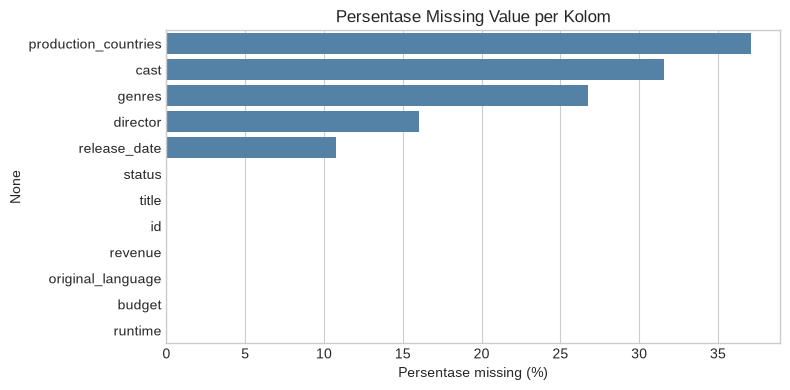

In [11]:
plt.figure(figsize=(8, 4))
sns.barplot(x=df_miss['persen'], y=df_miss.index, color='steelblue')
plt.xlabel('Persentase missing (%)')
plt.title('Persentase Missing Value per Kolom')
plt.tight_layout()
plt.show()

In [12]:
# Nilai nol / tidak wajar
anomali = pd.Series({
    'budget == 0': (df_relevan['budget'] == 0).sum(),
    'revenue == 0': (df_relevan['revenue'] == 0).sum(),
    'revenue < 0': (df_relevan['revenue'] < 0).sum(),
    'runtime == 0': (df_relevan['runtime'] == 0).sum(),
    'runtime > 300 menit': (df_relevan['runtime'] > 300).sum(),
    'release_date kosong': df_relevan['release_date'].isnull().sum(),
})
pd.DataFrame({'jumlah': anomali, 'persen': (anomali / len(df_relevan) * 100).round(2)})

,jumlah,persen
budget == 0,1173382,93.17
revenue == 0,1230439,97.70
revenue < 0,1,0.00
runtime == 0,291084,23.11
runtime > 300 menit,1657,0.13
release_date kosong,135262,10.74


In [13]:
# Sebaran status film dan pengecekan duplikat
print(df_relevan['status'].value_counts())
print("\nDuplikat berdasarkan id:", df_relevan.duplicated(subset='id').sum())
print("Duplikat berdasarkan title + release_date:", df_relevan.duplicated(subset=['title', 'release_date']).sum())

status
Released           1235518
Post Production       7470
In Production         7020
Planned               6951
Rumored               1258
Canceled              1211
Name: count, dtype: int64

Duplikat berdasarkan id: 0
Duplikat berdasarkan title + release_date: 9644


### Subset untuk analisis
Film dengan status Released serta budget, revenue, dan runtime > 0.

In [14]:
df_eda = df_relevan[
    (df_relevan['status'] == 'Released') &
    (df_relevan['budget'] > 0) &
    (df_relevan['revenue'] > 0) &
    (df_relevan['runtime'] > 0)
].copy()

df_eda['log_budget'] = np.log10(df_eda['budget'])
df_eda['log_revenue'] = np.log10(df_eda['revenue'])
tgl = pd.to_datetime(df_eda['release_date'], errors='coerce')
df_eda['release_year'] = tgl.dt.year
df_eda['release_month'] = tgl.dt.month

def ambil_pertama(s):
    return s.fillna('Unknown').astype(str).str.split(r'[,|]', regex=True).str[0].str.strip()

df_eda['primary_genre'] = ambil_pertama(df_eda['genres'])
df_eda['primary_country'] = ambil_pertama(df_eda['production_countries'])

print(f"Jumlah film pada subset EDA: {len(df_eda)} ({len(df_eda)/len(df_relevan)*100:.2f}% dari data awal)")
df_eda[['budget', 'revenue', 'runtime']].describe()

Jumlah film pada subset EDA: 16966 (1.35% dari data awal)


,budget,revenue,runtime
count,16966.00,16966.00,16966.00
mean,17054590.96,46043913.54,93.18
std,35179083.33,135700645.06,45.30
min,1.00,1.00,1.00
25%,87250.00,50000.00,85.00
50%,4000000.00,3900000.00,100.00
75%,18000000.00,30000000.00,116.00
max,999999999.00,2927449455.00,999.00


### 3.3 Analisis univariat

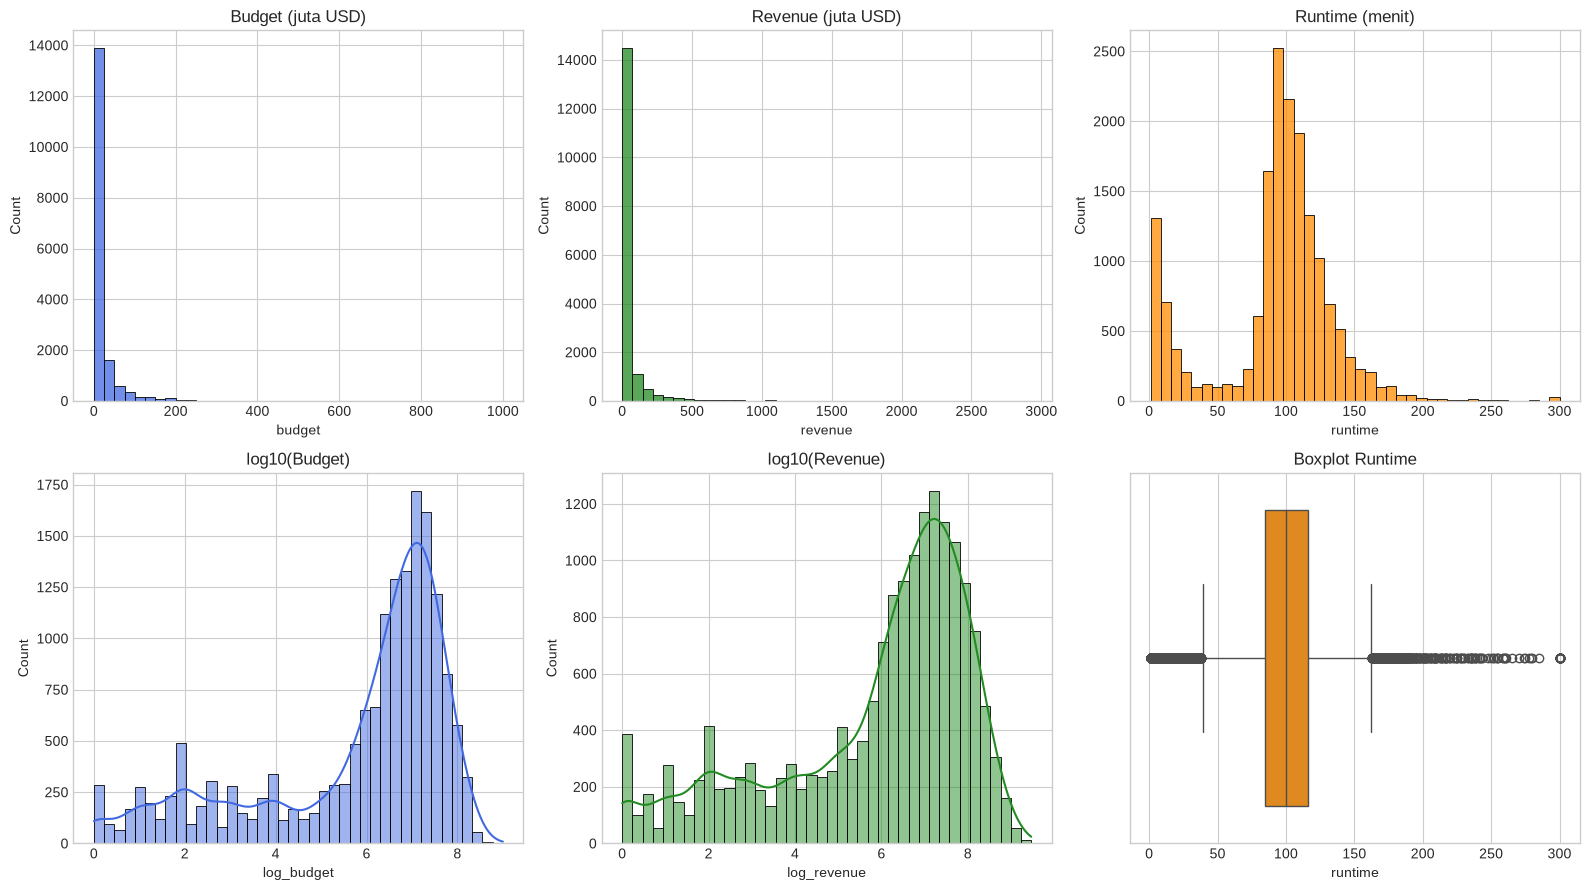

Skewness sebelum log  -> budget: 5.59, revenue: 7.32
Skewness sesudah log  -> budget: -1.19, revenue: -1.02


In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sns.histplot(df_eda['budget'] / 1e6, bins=40, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title('Budget (juta USD)')
sns.histplot(df_eda['revenue'] / 1e6, bins=40, ax=axes[0, 1], color='forestgreen')
axes[0, 1].set_title('Revenue (juta USD)')
sns.histplot(df_eda['runtime'].clip(upper=300), bins=40, ax=axes[0, 2], color='darkorange')
axes[0, 2].set_title('Runtime (menit)')
sns.histplot(df_eda['log_budget'], bins=40, kde=True, ax=axes[1, 0], color='royalblue')
axes[1, 0].set_title('log10(Budget)')
sns.histplot(df_eda['log_revenue'], bins=40, kde=True, ax=axes[1, 1], color='forestgreen')
axes[1, 1].set_title('log10(Revenue)')
sns.boxplot(x=df_eda['runtime'].clip(upper=300), ax=axes[1, 2], color='darkorange')
axes[1, 2].set_title('Boxplot Runtime')
plt.tight_layout()
plt.show()

print("Skewness sebelum log  -> budget: %.2f, revenue: %.2f" % (df_eda['budget'].skew(), df_eda['revenue'].skew()))
print("Skewness sesudah log  -> budget: %.2f, revenue: %.2f" % (df_eda['log_budget'].skew(), df_eda['log_revenue'].skew()))

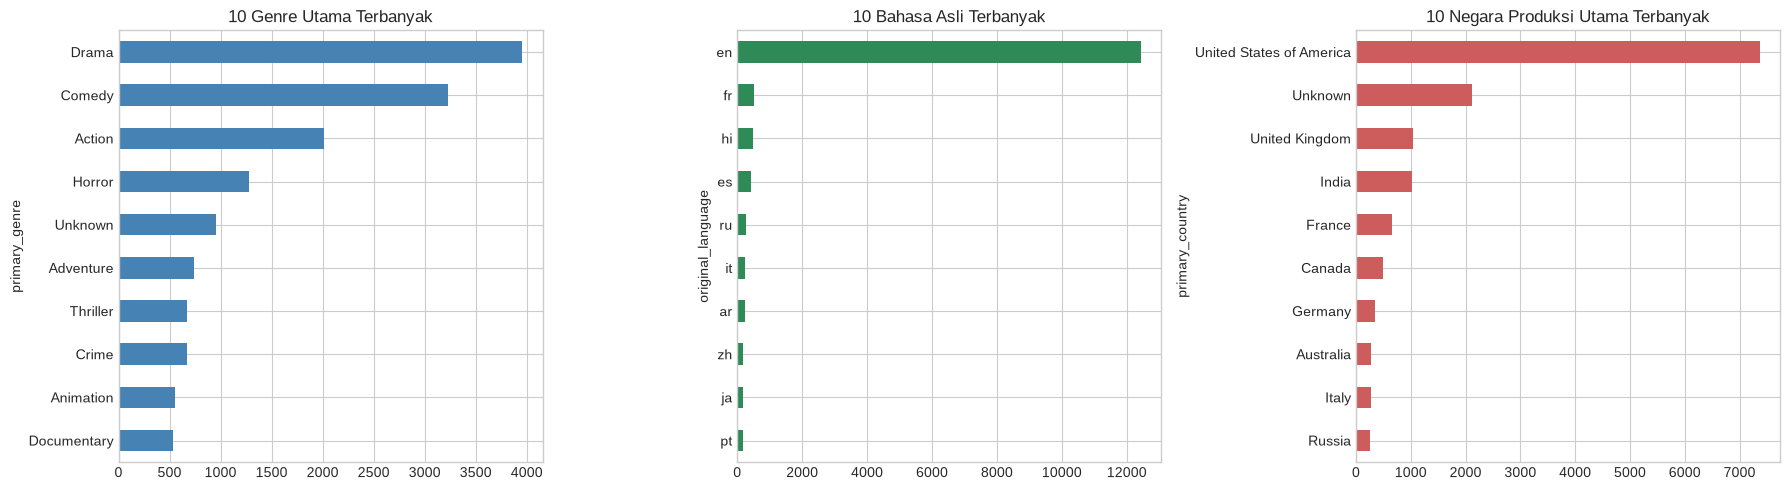

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
df_eda['primary_genre'].value_counts().head(10).sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('10 Genre Utama Terbanyak')
df_eda['original_language'].value_counts().head(10).sort_values().plot.barh(ax=axes[1], color='seagreen')
axes[1].set_title('10 Bahasa Asli Terbanyak')
df_eda['primary_country'].value_counts().head(10).sort_values().plot.barh(ax=axes[2], color='indianred')
axes[2].set_title('10 Negara Produksi Utama Terbanyak')
plt.tight_layout()
plt.show()

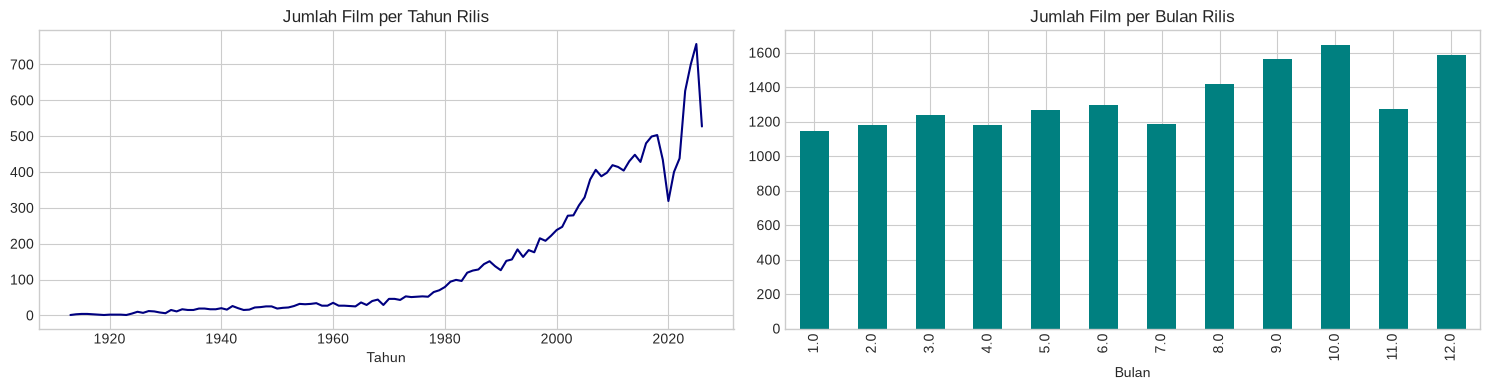

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
df_eda['release_year'].value_counts().sort_index().plot(ax=axes[0], color='navy')
axes[0].set_title('Jumlah Film per Tahun Rilis')
axes[0].set_xlabel('Tahun')
df_eda['release_month'].value_counts().sort_index().plot.bar(ax=axes[1], color='teal')
axes[1].set_title('Jumlah Film per Bulan Rilis')
axes[1].set_xlabel('Bulan')
plt.tight_layout()
plt.show()

### 3.4 Analisis bivariat terhadap revenue

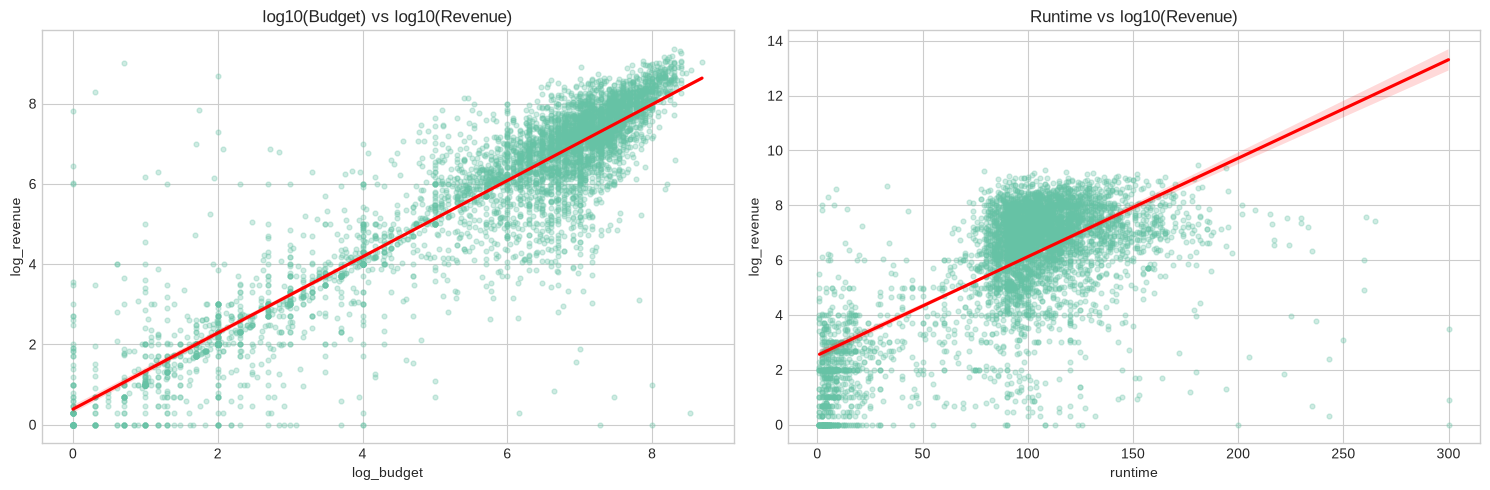

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.regplot(x='log_budget', y='log_revenue', data=df_eda.sample(min(5000, len(df_eda)), random_state=42),
            scatter_kws={'alpha': 0.3, 's': 12}, line_kws={'color': 'red'}, ax=axes[0])
axes[0].set_title('log10(Budget) vs log10(Revenue)')
sns.regplot(x='runtime', y='log_revenue', data=df_eda[df_eda['runtime'] <= 300].sample(min(5000, (df_eda['runtime'] <= 300).sum()), random_state=42),
            scatter_kws={'alpha': 0.3, 's': 12}, line_kws={'color': 'red'}, ax=axes[1])
axes[1].set_title('Runtime vs log10(Revenue)')
plt.tight_layout()
plt.show()

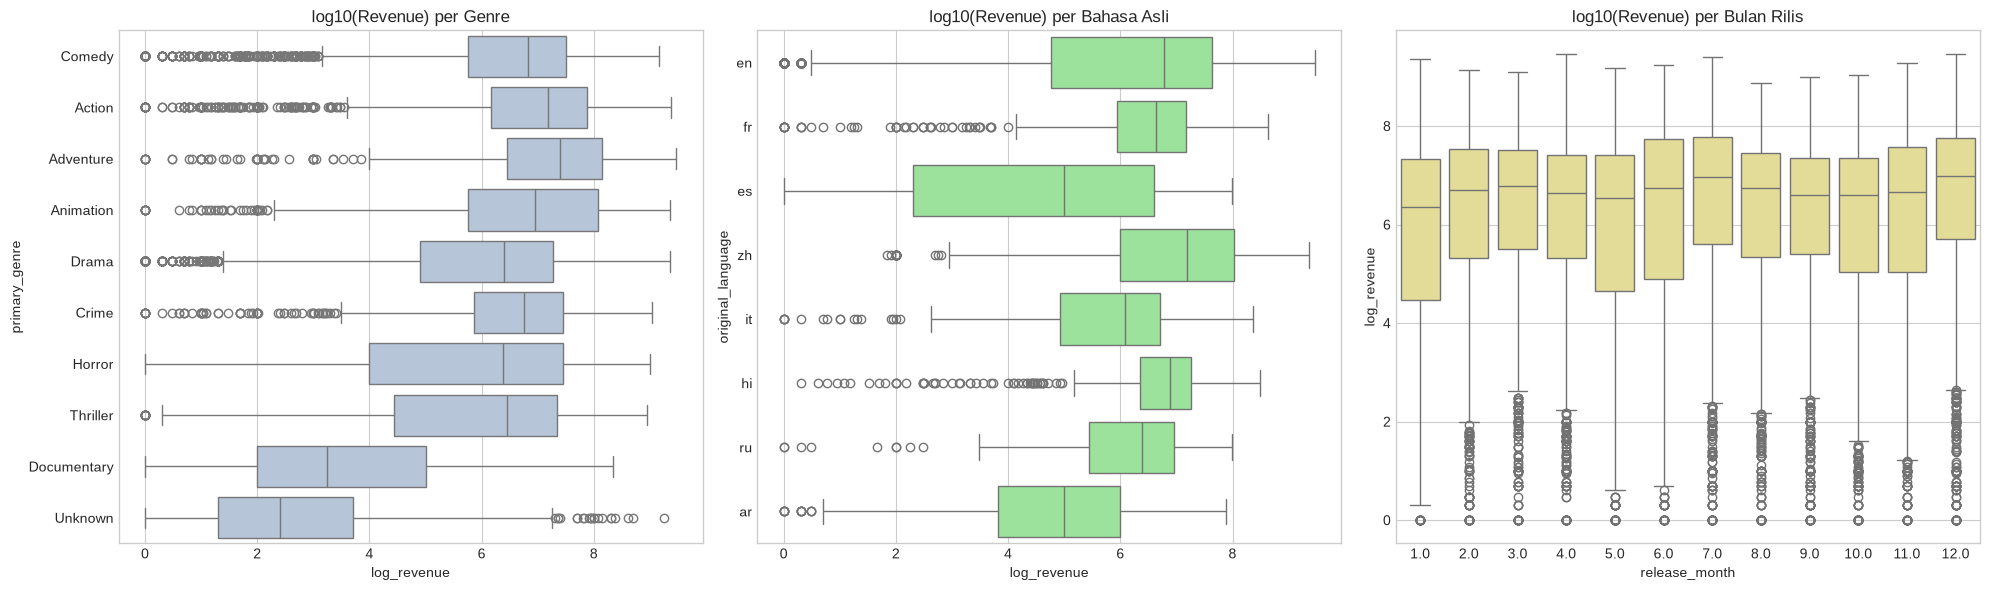

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
top_genre = df_eda['primary_genre'].value_counts().head(10).index
sns.boxplot(y='primary_genre', x='log_revenue', data=df_eda[df_eda['primary_genre'].isin(top_genre)], ax=axes[0], color='lightsteelblue')
axes[0].set_title('log10(Revenue) per Genre')
top_lang = df_eda['original_language'].value_counts().head(8).index
sns.boxplot(y='original_language', x='log_revenue', data=df_eda[df_eda['original_language'].isin(top_lang)], ax=axes[1], color='lightgreen')
axes[1].set_title('log10(Revenue) per Bahasa Asli')
sns.boxplot(x='release_month', y='log_revenue', data=df_eda, ax=axes[2], color='khaki')
axes[2].set_title('log10(Revenue) per Bulan Rilis')
plt.tight_layout()
plt.show()

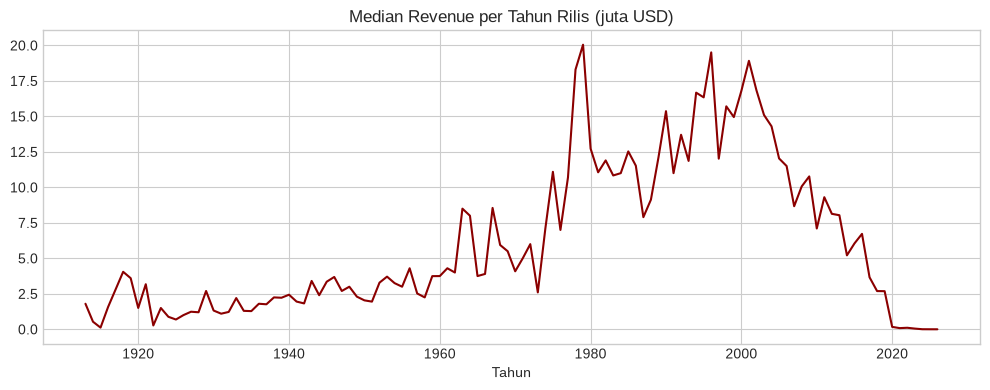

In [20]:
# Tren median revenue per tahun rilis (tanpa penyesuaian inflasi)
tren = df_eda.groupby('release_year')['revenue'].median() / 1e6
plt.figure(figsize=(10, 4))
tren.plot(color='darkred')
plt.title('Median Revenue per Tahun Rilis (juta USD)')
plt.xlabel('Tahun')
plt.tight_layout()
plt.show()

### 3.5 Korelasi

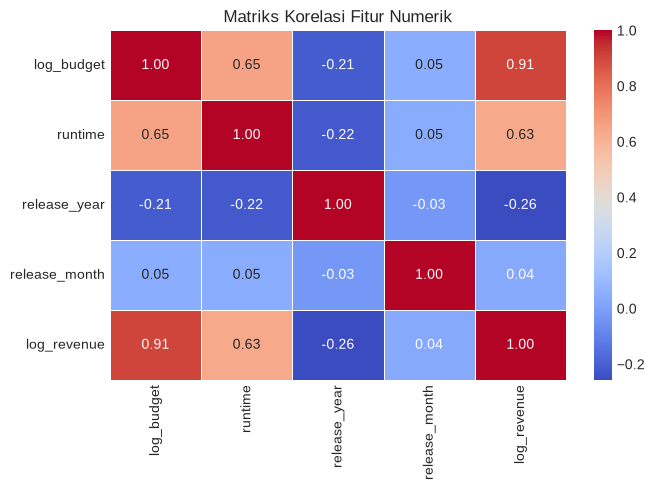

In [21]:
plt.figure(figsize=(7, 5))
sns.heatmap(df_eda[['log_budget', 'runtime', 'release_year', 'release_month', 'log_revenue']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Matriks Korelasi Fitur Numerik')
plt.tight_layout()
plt.show()

### 3.6 Outlier

In [22]:
def hitung_iqr(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.DataFrame({
    'jumlah_outlier': {k: hitung_iqr(df_eda[k]) for k in ['log_budget', 'log_revenue', 'runtime']},
    'persen': {k: round(hitung_iqr(df_eda[k]) / len(df_eda) * 100, 2) for k in ['log_budget', 'log_revenue', 'runtime']},
})

,jumlah_outlier,persen
log_budget,1137,6.70
log_revenue,532,3.14
runtime,3185,18.77


In [23]:
print("5 film dengan revenue tertinggi:")
print(df_eda.nlargest(5, 'revenue')[['title', 'release_year', 'budget', 'revenue']].to_string(index=False))
print("\n5 film dengan budget terkecil (kemungkinan salah catat):")
print(df_eda.nsmallest(5, 'budget')[['title', 'release_year', 'budget', 'revenue']].to_string(index=False))
print("\n5 film dengan runtime terpanjang:")
print(df_eda.nlargest(5, 'runtime')[['title', 'release_year', 'runtime']].to_string(index=False))

5 film dengan revenue tertinggi:
                    title  release_year       budget       revenue
        Avengers: Endgame       2019.00 356000000.00 2927449455.00
                   Avatar       2009.00 237000000.00 2923706026.00
Spider-Man: Brand New Day       2026.00 225000000.00 2512865567.00
 Avatar: The Way of Water       2022.00 460000000.00 2334484620.00
                 Ne Zha 2       2025.00  80000000.00 2270700370.00

5 film dengan budget terkecil (kemungkinan salah catat):
                      title  release_year  budget    revenue
      Photographing Fairies       1997.00    1.00       4.00
            The January Man       1989.00    1.00       4.00
The Xango from Baker Street       2001.00    1.00     410.00
               Little Ghost       1997.00    1.00      14.00
                 Between Us       2012.00    1.00 2755584.00

5 film dengan runtime terpanjang:
                                       title  release_year  runtime
Stable Ronaldo & Jynxzi's Minecraft Ma

### 3.7 Pengecekan bias representasi

In [24]:
rel = df_relevan[df_relevan['status'] == 'Released']
top_lang = df_eda['original_language'].value_counts().head(6).index
bias_bahasa = pd.DataFrame({
    'Data penuh Released (%)': rel['original_language'].value_counts(normalize=True)[top_lang] * 100,
    'Setelah filter finansial (%)': df_eda['original_language'].value_counts(normalize=True)[top_lang] * 100,
}).round(2)
bias_bahasa

,Data penuh Released (%),Setelah filter finansial (%)
original_language,,
en,48.10,73.32
fr,6.44,3.01
hi,0.82,2.78
es,6.31,2.52
ru,2.39,1.56
it,2.32,1.41


In [25]:
top_ctr = df_eda['primary_country'].value_counts().head(6).index
rel_ctr = ambil_pertama(rel['production_countries'])
pd.DataFrame({
    'Data penuh Released (%)': rel_ctr.value_counts(normalize=True).reindex(top_ctr) * 100,
    'Setelah filter finansial (%)': df_eda['primary_country'].value_counts(normalize=True)[top_ctr] * 100,
}).round(2)

,Data penuh Released (%),Setelah filter finansial (%)
primary_country,,
United States of America,14.20,43.43
Unknown,37.18,12.45
United Kingdom,3.95,6.16
India,2.25,5.98
France,4.05,3.91
Canada,2.24,2.87


### 3.8 Kesimpulan EDA dan keputusan untuk cleaning
* Nilai 0 pada `budget`/`revenue`/`runtime` dianggap data tidak tercatat, sehingga baris tersebut dibuang. Revenue negatif dibuang.
* Hanya film berstatus `Released` yang dipakai.
* `budget` dan `revenue` sangat miring ke kanan, sehingga ditransformasi log10 agar data tidak skewed.
* Nilai yang tidak wajar (budget/revenue sangat kecil, runtime sangat pendek atau panjang) dibatasi dengan ambang batas; blockbuster asli dipertahankan karena nilai valid.
* Kolom multi-nilai (`genres`, `production_countries`, `director`, `cast`) diambil nilai utamanya; kategori jarang digabung ke `Other`.
* Hasil filter hanya mencakup sebagian kecil dari seluruh dataset, sehingga bias seleksi dicatat sebagai keterbatasan.

---
# 4. DATA WRANGLING (CLEANING & PREPROCESSING)

### 4.1 Filter data tidak valid dan duplikat

In [26]:
df = df_relevan.copy()
n_awal = len(df)

df = df[
    (df['status'] == 'Released') &
    (df['budget'] >= 10_000) &
    (df['revenue'] >= 10_000) &
    (df['runtime'].between(40, 300)) &
    (df['release_date'].notna())
].copy()

# Hapus duplikat
df = df.drop_duplicates(subset='id')
df = df.drop_duplicates(subset=['title', 'release_date']).reset_index(drop=True)

print(f"Baris awal: {n_awal}")
print(f"Baris setelah filter dan hapus duplikat: {len(df)}")

Baris awal: 1259428
Baris setelah filter dan hapus duplikat: 12901


### 4.2 Feature engineering

In [27]:
# Tanggal rilis
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df = df[df['release_date'].notna()].copy()
df['release_year'] = df['release_date'].dt.year
df['release_month'] = df['release_date'].dt.month

# Transformasi log
df['log_budget'] = np.log10(df['budget'])
df['log_revenue'] = np.log10(df['revenue'])

# Nilai utama kolom multi-nilai
df['primary_genre'] = ambil_pertama(df['genres'])
df['primary_country'] = ambil_pertama(df['production_countries'])
df['primary_director'] = ambil_pertama(df['director'])
df['lead_actor'] = ambil_pertama(df['cast'])

# Gabungkan kategori jarang menjadi 'Other'
def gabung_jarang(s, top_n):
    top = s.value_counts().nlargest(top_n).index
    return s.where(s.isin(top), 'Other')

df['genre_grp'] = gabung_jarang(df['primary_genre'], 15)
df['language_grp'] = gabung_jarang(df['original_language'], 10)
df['country_grp'] = gabung_jarang(df['primary_country'], 10)

df[['title', 'release_year', 'release_month', 'genre_grp', 'language_grp', 'country_grp']].head()

,title,release_year,release_month,genre_grp,language_grp,country_grp
0,Four Rooms,1995,12,Comedy,en,United States of America
1,Judgment Night,1993,10,Action,en,United States of America
2,Star Wars,1977,5,Adventure,en,United States of America
3,Finding Nemo,2003,5,Animation,en,United States of America
4,Forrest Gump,1994,6,Comedy,en,United States of America


In [28]:
# Pengalaman sutradara: jumlah film yang sudah dirilis sebelumnya (dihitung dari seluruh data, tanpa memakai revenue)
d = df_relevan[['id', 'director', 'release_date']].copy()
d['release_date'] = pd.to_datetime(d['release_date'], errors='coerce')
d['dir1'] = ambil_pertama(d['director'])
d = d[(d['dir1'] != 'Unknown') & d['release_date'].notna()].sort_values('release_date')
d['director_prev_films'] = d.groupby('dir1').cumcount()
d = d.drop_duplicates('id').set_index('id')['director_prev_films']

df['director_prev_films'] = df['id'].map(d).fillna(0).astype(int)
df['director_prev_films'].describe()

count   12901.00
mean        9.22
std        15.19
min         0.00
25%         2.00
50%         5.00
75%        11.00
max       444.00
Name: director_prev_films, dtype: float64

### 4.3 Hasil akhir dan penyimpanan

In [29]:
kolom_akhir = [
    'id', 'title', 'release_date', 'release_year', 'release_month',
    'budget', 'log_budget', 'runtime',
    'genre_grp', 'language_grp', 'country_grp',
    'primary_director', 'lead_actor', 'director_prev_films',
    'revenue', 'log_revenue'
]
df_final = df[kolom_akhir].copy()

print("Missing value df_final:")
print(df_final.isnull().sum())
print()
df_final.info()

Missing value df_final:
id                     0
title                  0
release_date           0
release_year           0
release_month          0
budget                 0
log_budget             0
runtime                0
genre_grp              0
language_grp           0
country_grp            0
primary_director       0
lead_actor             0
director_prev_films    0
revenue                0
log_revenue            0
dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 12901 entries, 0 to 12900
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   id                   12901 non-null  int64         
 1   title                12901 non-null  str           
 2   release_date         12901 non-null  datetime64[us]
 3   release_year         12901 non-null  int32         
 4   release_month        12901 non-null  int32         
 5   budget               12901 non-null  float64       
 6   log

In [30]:
df_final[['budget', 'revenue', 'runtime', 'log_budget', 'log_revenue', 'director_prev_films']].describe()

,budget,revenue,runtime,log_budget,log_revenue,director_prev_films
count,12901.00,12901.00,12901.00,12901.00,12901.00,12901.00
mean,22060108.15,59942559.81,109.70,6.79,6.90,9.22
std,37223610.47,151711563.56,23.58,0.86,1.06,15.19
min,10000.00,10000.00,40.00,4.00,4.00,0.00
25%,2000000.00,1800000.00,94.00,6.30,6.26,2.00
50%,8733004.00,10686841.00,105.00,6.94,7.03,5.00
75%,25000000.00,47803176.00,120.00,7.40,7.68,11.00
max,658800000.00,2927449455.00,285.00,8.82,9.47,444.00


In [31]:
ringkasan = pd.DataFrame({
    'Aspek': ['Jumlah baris', 'Jumlah kolom', 'Baris dengan budget = 0 / revenue = 0', 'Missing value'],
    'Sebelum': [len(df_raw), df_raw.shape[1],
                int(((df_raw['budget'] == 0) | (df_raw['revenue'] == 0)).sum()),
                int(df_relevan.isnull().sum().sum())],
    'Sesudah': [len(df_final), df_final.shape[1],
                int(((df_final['budget'] == 0) | (df_final['revenue'] == 0)).sum()),
                int(df_final.isnull().sum().sum())],
})
ringkasan

,Aspek,Sebelum,Sesudah
0,Jumlah baris,1259428,12901
1,Jumlah kolom,30,16
2,Baris dengan budget = 0 / revenue = 0,1240567,0
3,Missing value,1538249,0


In [32]:
df_final.to_csv('data_bersih_tmdb.csv', index=False)
print("Data bersih disimpan ke data_bersih_tmdb.csv")

Data bersih disimpan ke data_bersih_tmdb.csv
